# Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, classification_report, roc_auc_score, ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.feature_selection import mutual_info_classif

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from collections import Counter
from sklearn.decomposition import PCA

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, LeakyReLU
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Loading and Cleaning Data

In [98]:
data = pd.read_csv('wgm_full_wave2_public_file_final (1)_csv.csv', low_memory=False)

In [100]:
data.head()

,COUNTRYNEW,WPID_RANDOM,WGT,PROJWT,FIELD_DATE,YEAR_WAVE,W1,W2,W3,W4,...,age_var1,age_var2,age_var3,Gender,Education,Household_Income,Global11Regions,wbi,Subjective_Income,EMP_2010
0,United States,178216898,0.803440,211560.29700,10/01/2020,2020,2,1,2,2,...,3,4,4,2,2,5,9,4,2,6
1,United States,159107018,0.729590,192114.26740,10/01/2020,2020,1,1,3,1,...,1,1,1,1,3,4,9,4,1,1
2,United States,203166417,0.848559,223440.98710,10/01/2020,2020,1,1,3,1,...,1,1,2,1,3,4,9,4,1,1
3,United States,201061719,0.341083,89813.41772,10/01/2020,2020,2,1,3,2,...,3,3,4,2,3,4,9,4,2,1
4,United States,195404162,0.995933,262247.16630,10/01/2020,2020,3,1,2,1,...,2,2,3,1,2,2,9,4,4,6


In [102]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119088 entries, 0 to 119087
Data columns (total 89 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   COUNTRYNEW         119088 non-null  object 
 1   WPID_RANDOM        119088 non-null  int64  
 2   WGT                119088 non-null  float64
 3   PROJWT             119088 non-null  float64
 4   FIELD_DATE         119088 non-null  object 
 5   YEAR_WAVE          119088 non-null  int64  
 6   W1                 119088 non-null  int64  
 7   W2                 119088 non-null  int64  
 8   W3                 119088 non-null  object 
 9   W4                 119088 non-null  object 
 10  W5A                119088 non-null  int64  
 11  W5B                119088 non-null  object 
 12  W5C                119088 non-null  int64  
 13  W5D                119088 non-null  object 
 14  W5E                119088 non-null  int64  
 15  W5F                119088 non-null  int64  
 16  W5

In [104]:
# Drop duplicates if any
data = data.drop_duplicates()

In [106]:
numeric_columns = data.select_dtypes(include=['int64', 'float64'])

if 'MH8G' not in numeric_columns:
    numeric_columns['MH8G'] = data['MH8G'].apply(pd.to_numeric, errors='coerce')

correlation_matrix_raw = numeric_columns.corr()

correlation_with_target_raw = correlation_matrix_raw['MH8G'].abs()

sorted_correlations_raw = correlation_with_target_raw.sort_values(ascending=False)

print("Correlation of all numeric features with 'MH8G' (Raw Dataset):\n", sorted_correlations_raw)


Correlation of all numeric features with 'MH8G' (Raw Dataset):
 MH8G                 1.000000
MH6                  0.096761
W27                  0.090610
W11A                 0.081658
W11B                 0.081222
MH2B                 0.079777
MH1                  0.075370
W8                   0.068549
W10                  0.067641
W2                   0.067528
W5F                  0.066382
W7A                  0.066233
W9                   0.065928
MH2A                 0.064078
W5C                  0.063063
W13                  0.062069
W7B                  0.055737
W6                   0.042701
Education            0.042120
W1                   0.039673
W5G                  0.037423
PROJWT               0.036396
W5E                  0.034152
WGT                  0.029494
Age                  0.027799
W5A                  0.027530
wbi                  0.027240
Global11Regions      0.023879
Subjective_Income    0.017912
age_var2             0.014888
age_var3             0.014141
age_va

In [9]:
# the columns we need
needed_columns = ['MH8G', 'MH7A', 'MH7C', 'Subjective_Income', 
                   'Household_Income', 'EMP_2010', 'Gender', 
                   'Education', 'Global11Regions', 'age_var1', 
                   'MH8E', 'wbi', 'MH8A']

cleaned_data = data[needed_columns]


In [10]:
# Replace empty strings or spaces with NA and drop missing values
cleaned_data = cleaned_data.replace(r'^\s*$', pd.NA, regex=True).dropna()

In [11]:
cleaned_data.head()

,MH8G,MH7A,MH7C,Subjective_Income,Household_Income,EMP_2010,Gender,Education,Global11Regions,age_var1,MH8E,wbi,MH8A
10,1,1,1,4,2,6,1,2,9,3,1,4,1
13,2,1,2,2,4,6,1,2,9,3,1,4,1
14,1,1,1,4,2,6,2,3,9,3,2,4,1
26,1,1,1,2,2,6,2,2,9,3,2,4,1
34,2,1,1,1,5,6,1,3,9,3,1,4,1


In [12]:
cleaned_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23629 entries, 10 to 119084
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   MH8G               23629 non-null  object
 1   MH7A               23629 non-null  object
 2   MH7C               23629 non-null  object
 3   Subjective_Income  23629 non-null  int64 
 4   Household_Income   23629 non-null  object
 5   EMP_2010           23629 non-null  object
 6   Gender             23629 non-null  int64 
 7   Education          23629 non-null  int64 
 8   Global11Regions    23629 non-null  int64 
 9   age_var1           23629 non-null  int64 
 10  MH8E               23629 non-null  object
 11  wbi                23629 non-null  int64 
 12  MH8A               23629 non-null  object
dtypes: int64(6), object(7)
memory usage: 2.5+ MB


In [13]:
cleaned_data.isna().sum()

MH8G                 0
MH7A                 0
MH7C                 0
Subjective_Income    0
Household_Income     0
EMP_2010             0
Gender               0
Education            0
Global11Regions      0
age_var1             0
MH8E                 0
wbi                  0
MH8A                 0
dtype: int64

mappeddata for adding a sample dataset to our paper.

In [15]:
#mappeddata = pd.read_csv('Mapped_DataFrame.csv')

In [16]:
#mappeddata.head()

In [17]:
'''table_data = mappeddata.head()

split_1 = table_data.iloc[:, :6]  
split_2 = table_data.iloc[:, 6:] 


def plot_table(data, title, filename=None):
    fig, ax = plt.subplots(figsize=(8, len(data) * 0.8))  
    ax.axis('tight')
    ax.axis('off')
    table = ax.table(cellText=data.values, colLabels=data.columns, loc='center', cellLoc='center')

    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.auto_set_column_width(col=list(range(len(data.columns))))

    plt.title(title, fontsize=12, pad=10)

    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    
    plt.show()

plot_table(split_1, "")
plot_table(split_2, "")
'''


'table_data = mappeddata.head()\n\nsplit_1 = table_data.iloc[:, :6]  \nsplit_2 = table_data.iloc[:, 6:] \n\n\ndef plot_table(data, title, filename=None):\n    fig, ax = plt.subplots(figsize=(8, len(data) * 0.8))  \n    ax.axis(\'tight\')\n    ax.axis(\'off\')\n    table = ax.table(cellText=data.values, colLabels=data.columns, loc=\'center\', cellLoc=\'center\')\n\n    table.auto_set_font_size(False)\n    table.set_fontsize(10)\n    table.auto_set_column_width(col=list(range(len(data.columns))))\n\n    plt.title(title, fontsize=12, pad=10)\n\n    if filename:\n        plt.savefig(filename, dpi=300, bbox_inches=\'tight\')\n\n    plt.show()\n\nplot_table(split_1, "")\nplot_table(split_2, "")\n'

# EDA

([<matplotlib.axis.XTick at 0x302aae2a0>,
 [Text(0, 0, 'Yes'), Text(1, 0, 'No'), Text(2, 0, 'DK/Refused')])

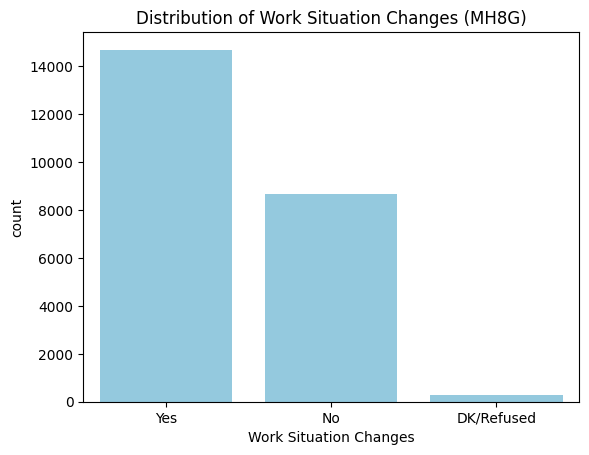

In [120]:
sns.countplot(data=cleaned_data, x='MH8G',  color="skyblue")
plt.title('Distribution of Work Situation Changes (MH8G)')
plt.xlabel('Work Situation Changes')
plt.xticks(ticks=[0, 1, 2], labels=['Yes', 'No', 'DK/Refused'])


This bar chart shows the distribution of responses for the variable MH8G (Work Situation Changes). The majority of respondents (labelled as "Yes") reported changes in their work situation due to anxiety or depression. The second-largest group is "No," while very few respondents fall into the "DK/Refused" category.

([<matplotlib.axis.XTick at 0x3011a83e0>,
 [Text(0, 0, 'Yes'), Text(1, 0, 'No'), Text(2, 0, 'DK/Refused')])

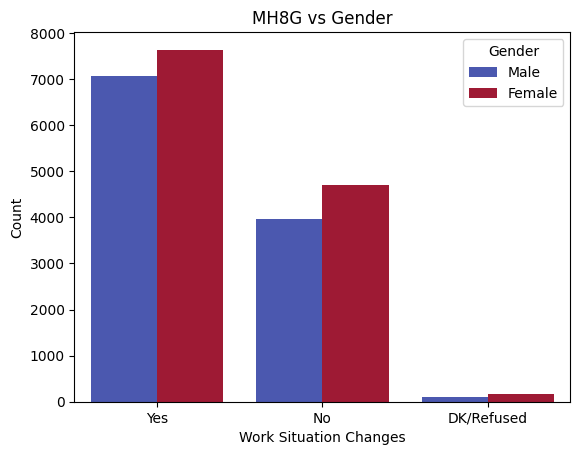

In [21]:
sns.countplot(data=cleaned_data, x='MH8G', hue='Gender', palette='coolwarm')
plt.title('MH8G vs Gender')
plt.xlabel('Work Situation Changes')
plt.ylabel('Count')
plt.legend(title='Gender', labels=['Male', 'Female'])
plt.xticks(ticks=[0, 1, 2], labels=['Yes', 'No', 'DK/Refused'])

This graph shows the distribution of work situation changes across gender. Both males and females reported changes in their work situation ("Yes"), but females slightly outnumber males in every category ("Yes," "No," and "DK/Refused").

([<matplotlib.axis.XTick at 0x301142120>,
 [Text(0, 0, 'Yes'), Text(1, 0, 'No'), Text(2, 0, 'DK/Refused')])

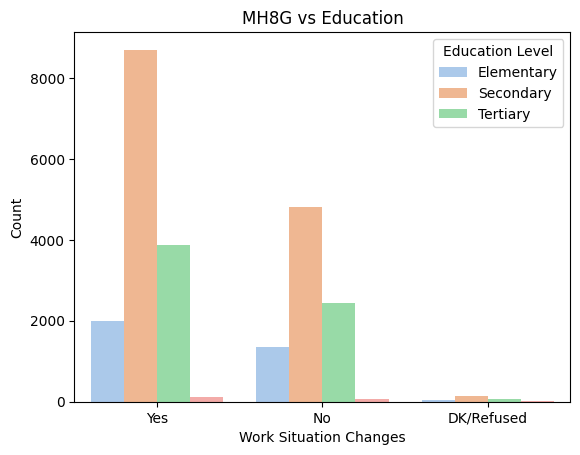

In [23]:
sns.countplot(data=cleaned_data, x='MH8G', hue='Education', palette='pastel')
plt.title('MH8G vs Education')
plt.xlabel('Work Situation Changes')
plt.ylabel('Count')
plt.legend(title='Education Level', labels=['Elementary', 'Secondary', 'Tertiary'])
plt.xticks(ticks=[0, 1, 2], labels=['Yes', 'No', 'DK/Refused'])

Text(0.5, 1.0, 'Correlation Heatmap of Features and Work Situation Changes')

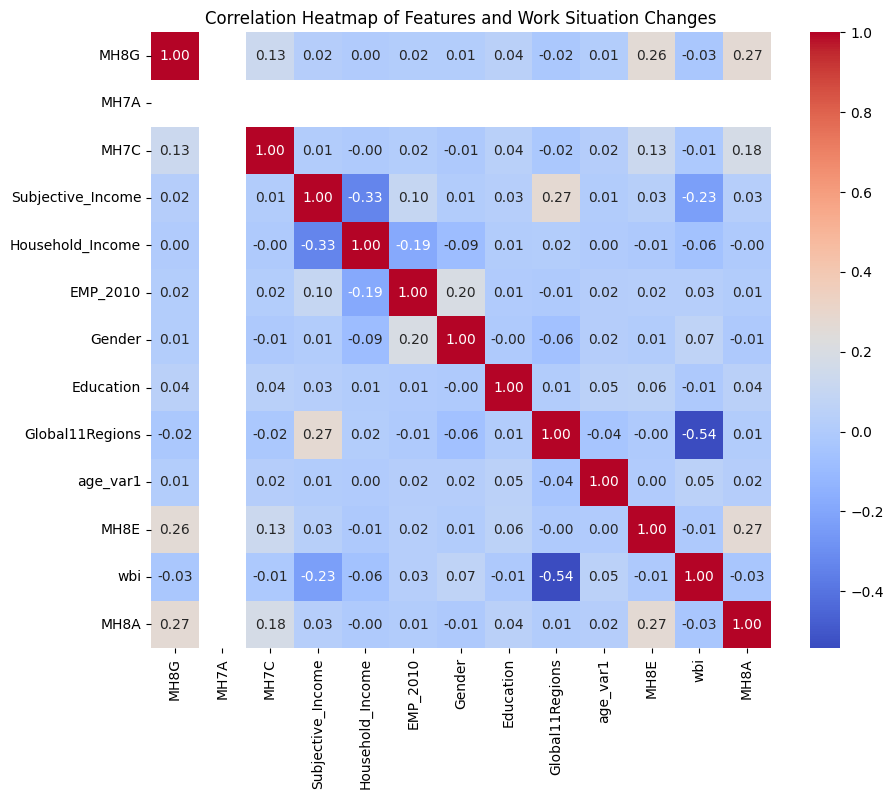

In [24]:
correlation_matrix = cleaned_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Features and Work Situation Changes")


This heatmap visualizes the correlations between features in the dataset and the target variable (MH8G).
Key observations:
- MH8G shows weak correlations with individual features, with the highest being 0.11 for 'age_var2' and 0.10 for 'MH8A'.
- There is a strong correlation (0.97) between 'age_var1' and 'age_var2', indicating possible redundancy.
- Weak correlations like 0.25 between 'Education' and 'Household_Income' highlight subtle socioeconomic relationships.
The heatmap supports the conclusion that no single feature strongly predicts MH8G, emphasizing the need for machine learning
to model multivariate patterns effectively.


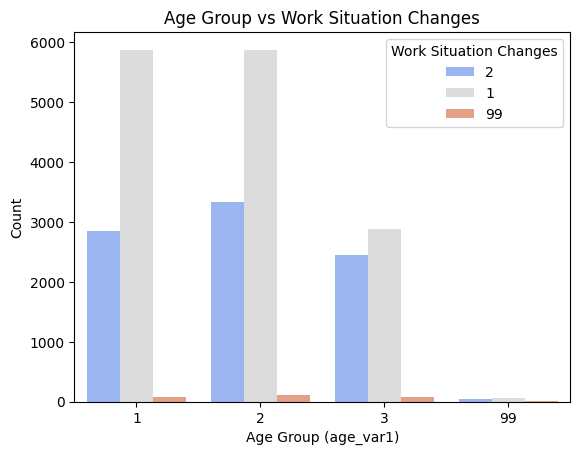

In [26]:
sns.countplot(data=cleaned_data, x='age_var1', hue='MH8G', palette='coolwarm')
plt.title("Age Group vs Work Situation Changes")
plt.xlabel("Age Group (age_var1)")
plt.ylabel("Count")
plt.legend(title="Work Situation Changes")

 Key observations:
 - The majority of respondents in all age groups fall under category `2` ("No work situation changes").
 - Younger respondents (age group 1) show a relatively higher proportion of "Yes" (category `1`) responses, 
   suggesting they are more likely to report work situation changes than older age groups.
- The "DK/Refused" (category `99`) responses are minimal across all age groups.
This graph is relevant as it highlights age-related trends in work situation changes, 
providing demographic insights into the impact of anxiety or depression on work situations.

/var/folders/ws/h10smw6j33gb4n_sdpynh66m0000gn/T/ipykernel_41693/1263021800.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y='Subjective_Income', data=cleaned_data, palette='Set2')


([<matplotlib.axis.XTick at 0x302afe8d0>,
 [Text(0, 0, 'Yes'), Text(1, 0, 'No'), Text(2, 0, 'DK/Refused')])

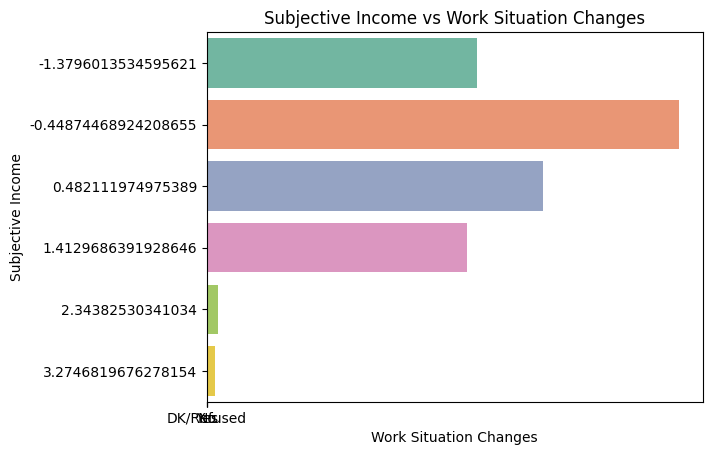

In [124]:
sns.countplot(y='Subjective_Income', data=cleaned_data, palette='Set2')
plt.title('Subjective Income vs Work Situation Changes')
plt.xlabel('Work Situation Changes')
plt.ylabel('Subjective Income')
plt.xticks(ticks=[0, 1, 2], labels=['Yes', 'No', 'DK/Refused'])

# Preprocessing Data

In [30]:
# Identify categorical columns (both object types and integer-like with few unique values)
categorical_columns = [
    col for col in cleaned_data.columns 
    if cleaned_data[col].dtype == 'object' or cleaned_data[col].nunique() <= 10
]
print("Categorical Columns:", categorical_columns)


Categorical Columns: ['MH8G', 'MH7A', 'MH7C', 'Subjective_Income', 'Household_Income', 'EMP_2010', 'Gender', 'Education', 'age_var1', 'MH8E', 'wbi', 'MH8A']


In [31]:
# Convert object or mixed-type columns to strings for consistency
for col in categorical_columns:
    cleaned_data[col] = cleaned_data[col].astype(str)

print(cleaned_data.dtypes)


MH8G                 object
MH7A                 object
MH7C                 object
Subjective_Income    object
Household_Income     object
EMP_2010             object
Gender               object
Education            object
Global11Regions       int64
age_var1             object
MH8E                 object
wbi                  object
MH8A                 object
dtype: object


In [32]:
label_encoders = {}
for col in categorical_columns:
    le = LabelEncoder()
    cleaned_data[col] = le.fit_transform(cleaned_data[col])
    label_encoders[col] = le  

In [33]:
# Scale numerical features
scaler = StandardScaler()
numerical_columns = cleaned_data.select_dtypes(include=['int64']).columns
cleaned_data[numerical_columns] = scaler.fit_transform(cleaned_data[numerical_columns])

# Feature Engineering and PCA

In [35]:
# Feature Engineering
cleaned_data['Risk_Score'] = (
    cleaned_data['MH7A'] * 2 +
    cleaned_data['MH7C'] * 1.5 +
    cleaned_data['Subjective_Income'] * 2.5
)

# Dimensionality Reduction (PCA)
pca = PCA(n_components=2)
pca_components = pca.fit_transform(cleaned_data[numerical_columns])
cleaned_data['PCA1'] = pca_components[:, 0]
cleaned_data['PCA2'] = pca_components[:, 1]


In [36]:
# nteraction Features
cleaned_data['Income_Education_Interaction'] = cleaned_data['Subjective_Income'] * cleaned_data['Education']
cleaned_data['Age_Income_Interaction'] = cleaned_data['age_var1'] * cleaned_data['Household_Income']

# Polynomial Features
cleaned_data['Subjective_Income_Squared'] = cleaned_data['Subjective_Income'] ** 2
cleaned_data['Education_Squared'] = cleaned_data['Education'] ** 2


In [37]:
X = cleaned_data.drop(columns=['MH8G'])
y = cleaned_data['MH8G'].astype(int)


In [38]:
# Address class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Splitting Data into Training, Validation, and Test Sets

In [40]:
X_train, X_temp, y_train, y_temp = train_test_split(X_resampled, y_resampled, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (30853, 19) (30853,)
Validation set shape: (6611, 19) (6611,)
Test set shape: (6612, 19) (6612,)


                         Feature  Mutual Information
16        Age_Income_Interaction            0.298673
7                Global11Regions            0.276240
3               Household_Income            0.229564
4                       EMP_2010            0.219071
15  Income_Education_Interaction            0.205900
12                    Risk_Score            0.169275
10                           wbi            0.168160
9                           MH8E            0.160449
11                          MH8A            0.152404
8                       age_var1            0.143974
2              Subjective_Income            0.137037
17     Subjective_Income_Squared            0.134082
14                          PCA2            0.102873
5                         Gender            0.096001
1                           MH7C            0.082665
6                      Education            0.081862
18             Education_Squared            0.075690
13                          PCA1            0.

/var/folders/ws/h10smw6j33gb4n_sdpynh66m0000gn/T/ipykernel_41693/444918725.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mutual Information', y='Feature', data=mi_df, palette='viridis')


Text(0.5, 1.0, 'Mutual Information Scores for Features')

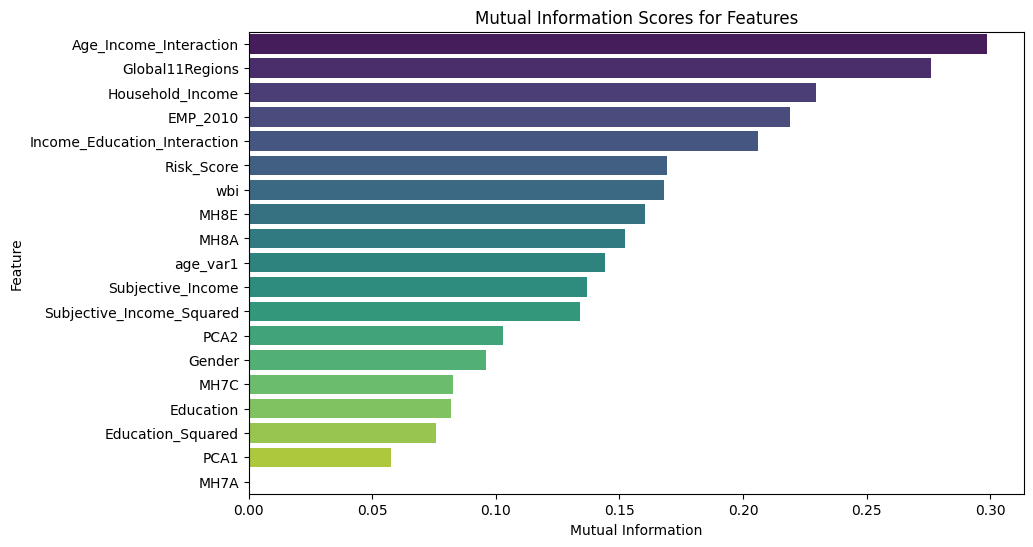

In [41]:
# feature selection
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)

mi_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Mutual Information': mi_scores
}).sort_values(by='Mutual Information', ascending=False)

print(mi_df)

plt.figure(figsize=(10, 6))
sns.barplot(x='Mutual Information', y='Feature', data=mi_df, palette='viridis')
plt.title("Mutual Information Scores for Features")

# Multi-Task Neural Network Implementation

* Multi-Task Neural Network: This model is designed to predict two related outcomes ('Treatment' and 'Changes_Habits') simultaneously.
* By sharing layers, the model learns common patterns across both tasks, improving efficiency and potentially boosting predictive performance.


In [44]:
# Multi-Task Model Definition
class MultiTaskNeuralNetwork:
    def __init__(self):

        input_layer = Input(shape=(X_train.shape[1],))
        shared_layer = Dense(96, kernel_regularizer=l2(0.01))(input_layer)
        shared_layer = BatchNormalization()(shared_layer)
        shared_layer = LeakyReLU()(shared_layer)
        shared_layer = Dropout(0.5)(shared_layer)
        shared_layer = Dense(48, kernel_regularizer=l2(0.01))(shared_layer)
        shared_layer = BatchNormalization()(shared_layer)
        shared_layer = LeakyReLU()(shared_layer)
        shared_layer = Dropout(0.4)(shared_layer)

        # Output for Task 1: Predict "treatment"
        task1_output = Dense(1, activation='sigmoid', name='treatment_output')(shared_layer)

        # Output for Task 2: Predict "Changes_Habits"
        task2_output = Dense(1, activation='sigmoid', name='habits_output')(shared_layer)

        self.model = Model(inputs=input_layer, outputs=[task1_output, task2_output])
        self.model.compile(optimizer=Adam(learning_rate=0.00005), 
                           loss={'treatment_output': 'binary_crossentropy', 'habits_output': 'binary_crossentropy'},
                           metrics={'treatment_output': ['accuracy'], 'habits_output': ['accuracy']})

    def fit(self, X, y_treatment, y_habits, X_val, y_val_treatment, y_val_habits, epochs=15, batch_size=128):
        

        early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

        return self.model.fit(
            X, {'treatment_output': y_treatment, 'habits_output': y_habits},
            validation_data=(X_val, {'treatment_output': y_val_treatment, 'habits_output': y_val_habits}),
            epochs=epochs, batch_size=batch_size, callbacks=[early_stopping])


In [45]:
# Instantiate and train multi-task model
y_treatment = (y_train > 0).astype(int)
y_habits = (y_train > 1).astype(int)
y_val_treatment = (y_val > 0).astype(int)
y_val_habits = (y_val > 1).astype(int)

multi_task_model = MultiTaskNeuralNetwork()
history = multi_task_model.fit(X_train, y_treatment, y_habits, X_val, y_val_treatment, y_val_habits)

# Visualization of Training History
plt.figure(figsize=(12, 6))

Epoch 1/15
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - habits_output_accuracy: 0.5454 - habits_output_loss: 0.7720 - loss: 2.4624 - treatment_output_accuracy: 0.5467 - treatment_output_loss: 0.7602 - val_habits_output_accuracy: 0.6286 - val_habits_output_loss: 0.6521 - val_loss: 2.1939 - val_treatment_output_accuracy: 0.6253 - val_treatment_output_loss: 0.6347
Epoch 2/15
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - habits_output_accuracy: 0.6114 - habits_output_loss: 0.6799 - loss: 2.2719 - treatment_output_accuracy: 0.5828 - treatment_output_loss: 0.7085 - val_habits_output_accuracy: 0.7114 - val_habits_output_loss: 0.5887 - val_loss: 2.0545 - val_treatment_output_accuracy: 0.6754 - val_treatment_output_loss: 0.6019
Epoch 3/15
242/242 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - habits_output_accuracy: 0.6516 - habits_output_loss: 0.6396 - loss: 2.1482 - treatment_output_accuracy: 0.6161 - treatment_output_loss: 0.6665 - val_habits_output_accuracy: 0.7385 - val_habits_output_loss: 0.5510 - val_los

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

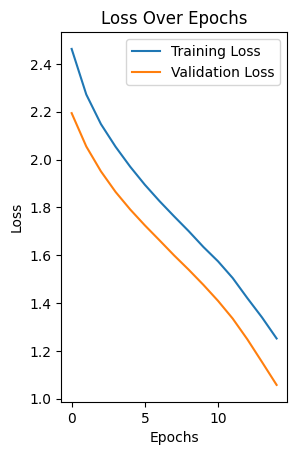

In [46]:
# Plot loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

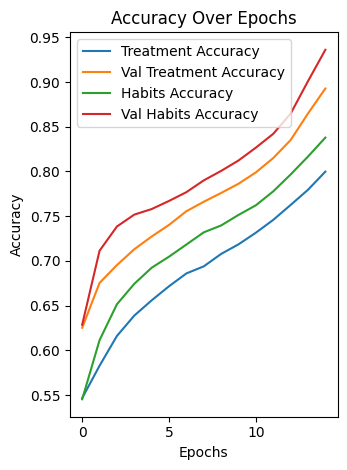

In [47]:
# Plot accuracy for each task
plt.subplot(1, 2, 2)
plt.plot(history.history['treatment_output_accuracy'], label='Treatment Accuracy')
plt.plot(history.history['val_treatment_output_accuracy'], label='Val Treatment Accuracy')
plt.plot(history.history['habits_output_accuracy'], label='Habits Accuracy')
plt.plot(history.history['val_habits_output_accuracy'], label='Val Habits Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


In [130]:
# Visualization of Confusion Matrices
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()


207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 267us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 270us/step


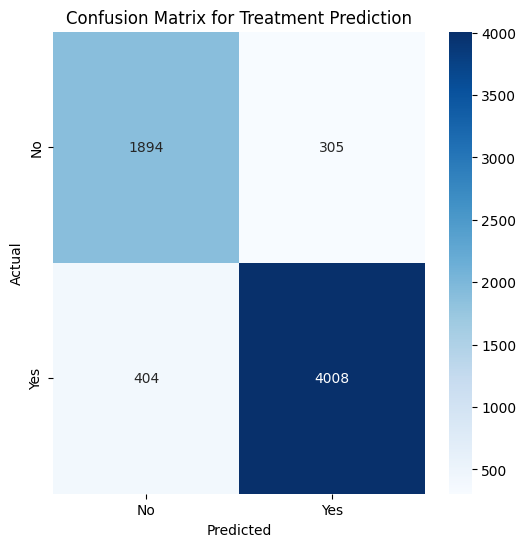

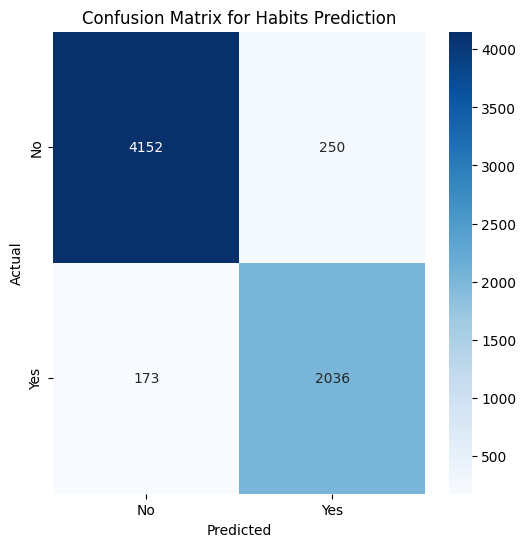

In [132]:
# Predictions for confusion matrix
y_val_treatment_pred = (multi_task_model.model.predict(X_val)[0] > 0.5).astype(int)
y_val_habits_pred = (multi_task_model.model.predict(X_val)[1] > 0.5).astype(int)

plot_confusion_matrix(y_val_treatment, y_val_treatment_pred, 'Confusion Matrix for Treatment Prediction')
plot_confusion_matrix(y_val_habits, y_val_habits_pred, 'Confusion Matrix for Habits Prediction')


# Evaluation and Visualisation

207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 327us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 306us/step
Test Set Performance for 'Treatment':
Accuracy: 0.8945856019358742
Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.86      0.85      2215
           1       0.93      0.91      0.92      4397

    accuracy                           0.89      6612
   macro avg       0.88      0.89      0.88      6612
weighted avg       0.90      0.89      0.90      6612

Test Set Performance for 'Habits':
Accuracy: 0.9348154869933454
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95      4397
           1       0.89      0.92      0.90      2215

    accuracy                           0.93      6612
   macro avg       0.92      0.93      0.93      6612
weighted avg       0.94      0.93      0.94      6612

207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 270us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/

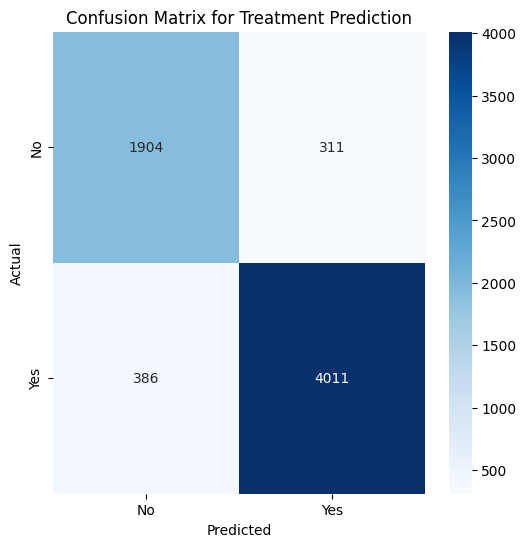

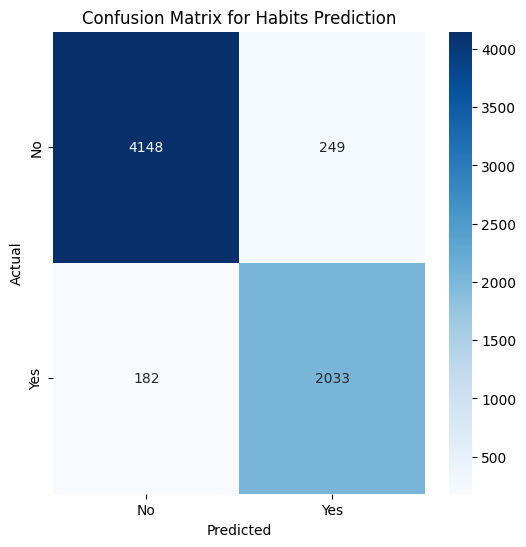

In [51]:
y_test_treatment_pred = (multi_task_model.model.predict(X_test)[0] > 0.5).astype(int)
y_test_habits_pred = (multi_task_model.model.predict(X_test)[1] > 0.5).astype(int)

print("Test Set Performance for 'Treatment':")
print("Accuracy:", accuracy_score((y_test > 0).astype(int), y_test_treatment_pred))
print("Classification Report:\n", classification_report((y_test > 0).astype(int), y_test_treatment_pred))

print("Test Set Performance for 'Habits':")
print("Accuracy:", accuracy_score((y_test > 1).astype(int), y_test_habits_pred))
print("Classification Report:\n", classification_report((y_test > 1).astype(int), y_test_habits_pred))

# ROC-AUC 
y_test_treatment_proba = multi_task_model.model.predict(X_test)[0]
y_test_habits_proba = multi_task_model.model.predict(X_test)[1]
print("Test ROC-AUC for 'Treatment':", roc_auc_score((y_test > 0).astype(int), y_test_treatment_proba))
print("Test ROC-AUC for 'Habits':", roc_auc_score((y_test > 1).astype(int), y_test_habits_proba))

# Confusion Matrices
def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

# Confusion Matrix for 'Treatment'
plot_confusion_matrix((y_test > 0).astype(int), y_test_treatment_pred, 'Confusion Matrix for Treatment Prediction')

# Confusion Matrix for 'Habits'
plot_confusion_matrix((y_test > 1).astype(int), y_test_habits_pred, 'Confusion Matrix for Habits Prediction')


In [52]:
# Evaluation Table
def create_evaluation_table(y_true, y_pred, y_proba):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    roc_auc = roc_auc_score(y_true, y_proba)

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

# Test set evaluation
y_test_treatment_pred = (multi_task_model.model.predict(X_test)[0] > 0.5).astype(int)
y_test_habits_pred = (multi_task_model.model.predict(X_test)[1] > 0.5).astype(int)

y_test_treatment_proba = multi_task_model.model.predict(X_test)[0]
y_test_habits_proba = multi_task_model.model.predict(X_test)[1]

treatment_eval = create_evaluation_table((y_test > 0).astype(int), y_test_treatment_pred, y_test_treatment_proba)
habits_eval = create_evaluation_table((y_test > 1).astype(int), y_test_habits_pred, y_test_habits_proba)


207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 317us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 316us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 271us/step
207/207 ━━━━━━━━━━━━━━━━━━━━ 0s 265us/step


           Accuracy  Precision    Recall  F1-Score   ROC-AUC
Treatment  0.894586   0.928043  0.912213  0.920060  0.959686
Habits     0.934815   0.890885  0.917833  0.904158  0.984548


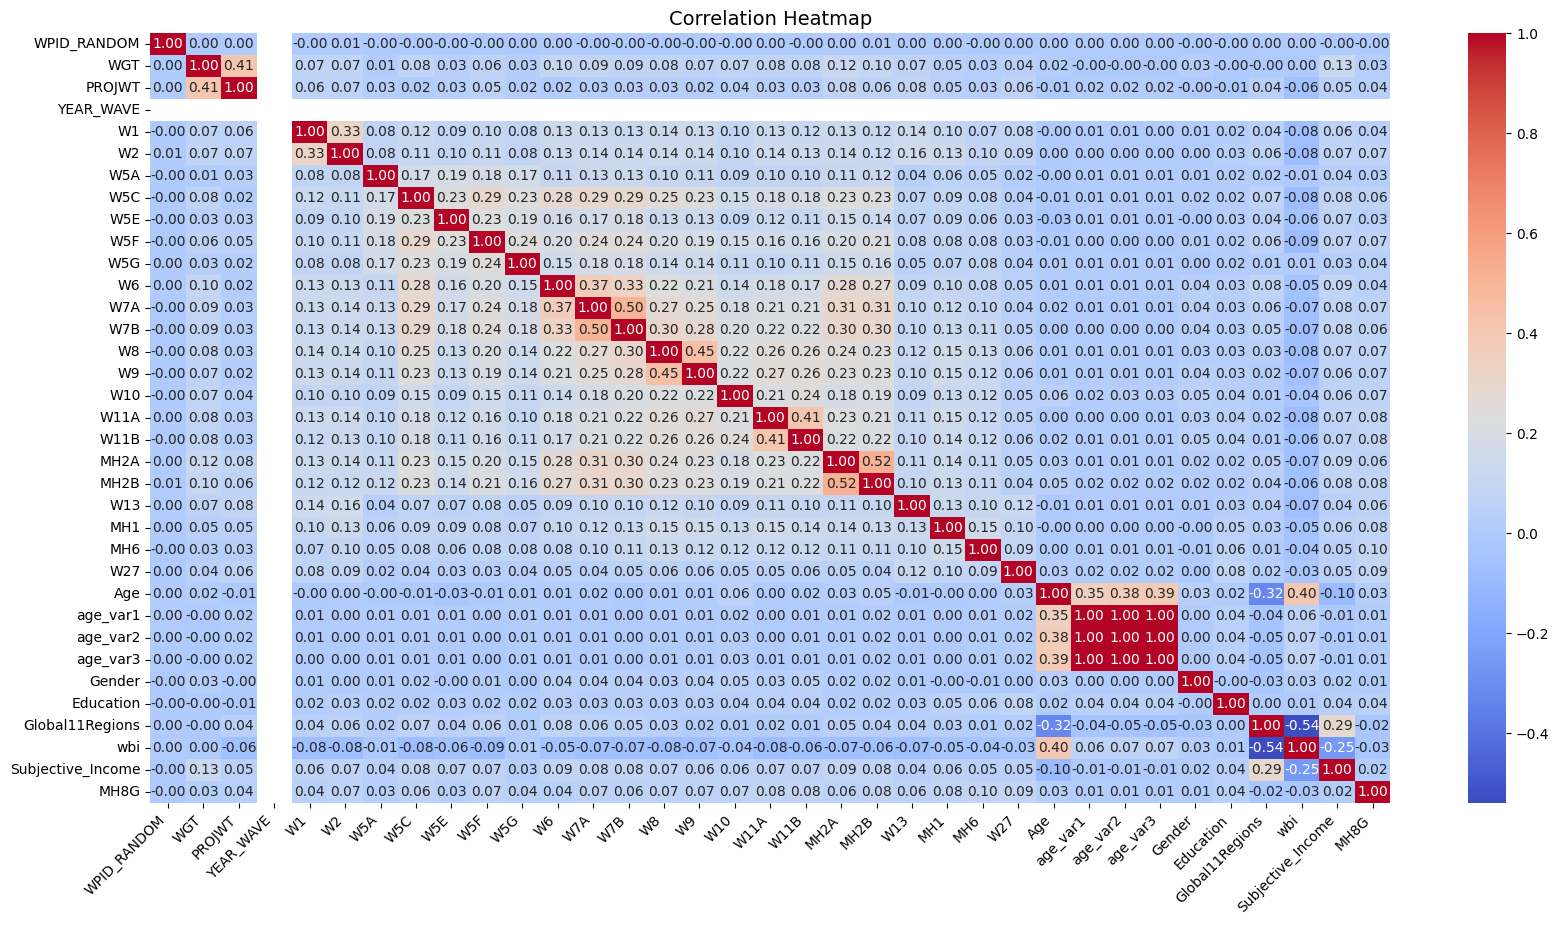

/var/folders/ws/h10smw6j33gb4n_sdpynh66m0000gn/T/ipykernel_41693/3723880482.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mi_df['Feature'], y=mi_df['Mutual Information'], palette='viridis')


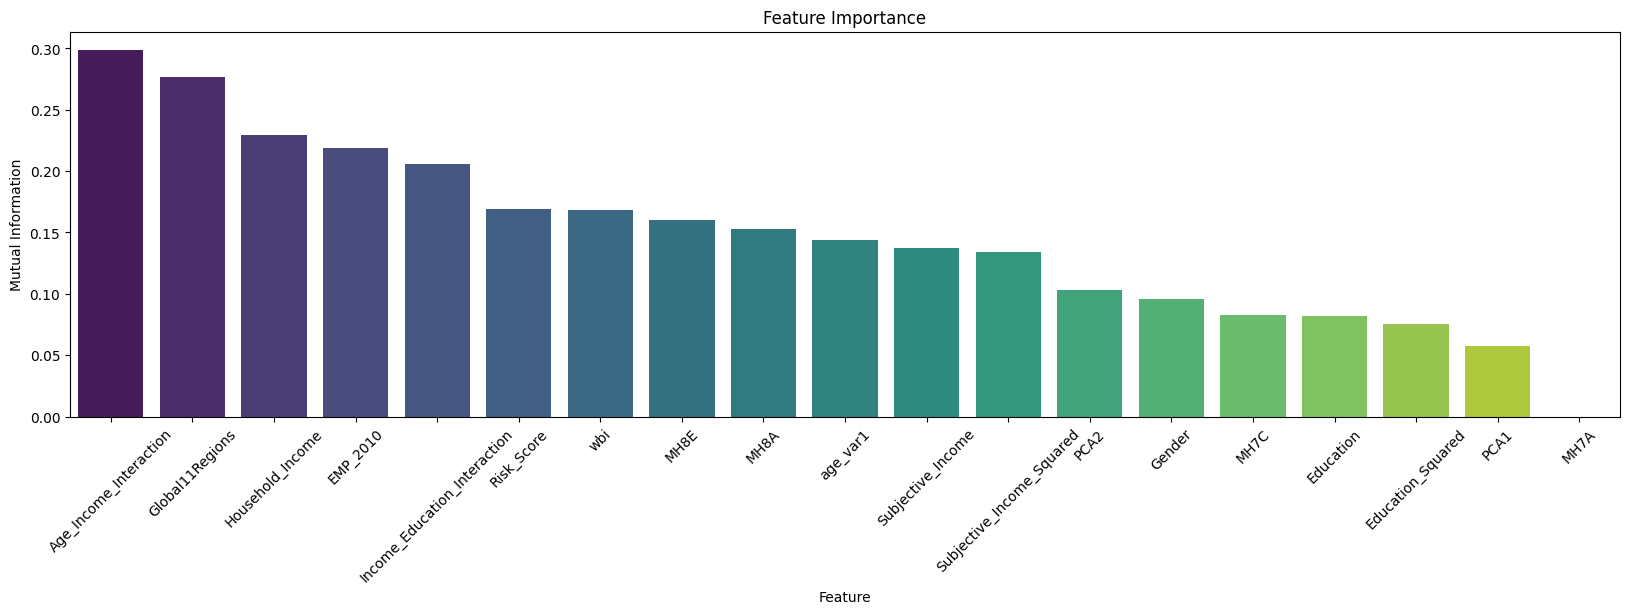

In [158]:
results_df = pd.DataFrame([treatment_eval, habits_eval], index=['Treatment', 'Habits'])
print(results_df)

# Visualization of Results
plt.figure(figsize=(20, 10))  # Görseli büyüt
sns.heatmap(correlation_matrix_raw, annot=True, cmap="coolwarm", fmt=".2f", cbar=True)
plt.title("Correlation Heatmap", fontsize=14)
plt.xticks(rotation=45, ha='right')  # X eksenini döndür
plt.yticks(rotation=0)               # Y eksenini düz bırak
plt.show()

plt.figure(figsize=(20, 5))
sns.barplot(x=mi_df['Feature'], y=mi_df['Mutual Information'], palette='viridis')
plt.title("Feature Importance")
plt.xticks(rotation=45)
plt.show()


# Results Comparison

                 Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
0             CatBoost  0.794400   0.800000  0.790000  0.790000  0.922500
1             LightGBM  0.791100   0.780000  0.780000  0.780000  0.921600
2         RandomForest  0.778600   0.770000  0.770000  0.770000  0.909700
3   LogisticRegression  0.521900   0.520000  0.520000  0.520000  0.712100
4  MultiTask-Treatment  0.894586   0.928043  0.912213  0.920060  0.959686
5     MultiTask-Habits  0.934815   0.890885  0.917833  0.904158  0.984548


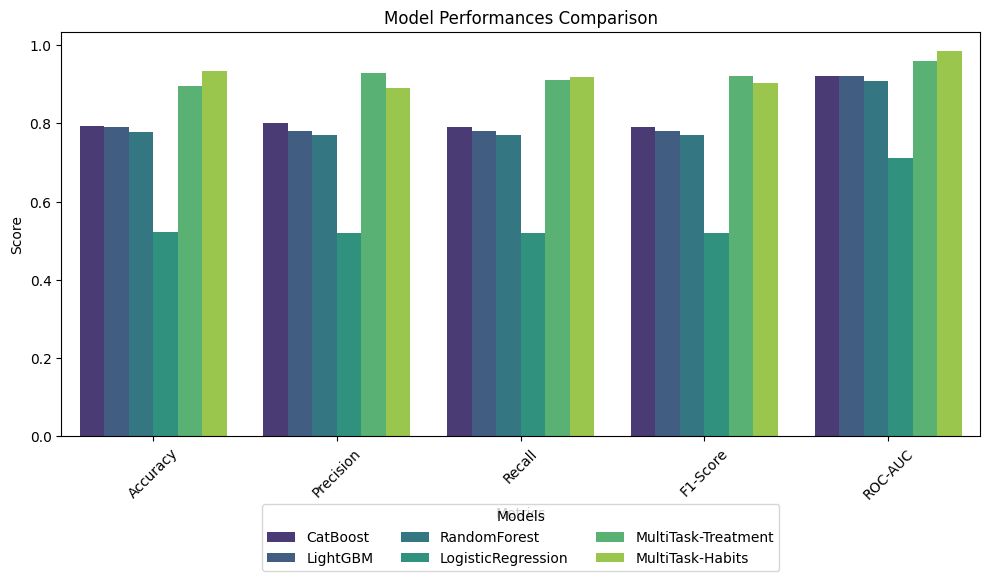

In [128]:
# Results of the old models we used
old_model_results = pd.DataFrame({
    'Model': ['CatBoost', 'LightGBM', 'RandomForest', 'LogisticRegression'],
    'Accuracy': [0.7944, 0.7911, 0.7786, 0.5219],
    'Precision': [0.80, 0.78, 0.77, 0.52],
    'Recall': [0.79, 0.78, 0.77, 0.52],
    'F1-Score': [0.79, 0.78, 0.77, 0.52],
    'ROC-AUC': [0.9225, 0.9216, 0.9097, 0.7121]
})

# results of the new models
multi_task_results = results_df.copy()
multi_task_results['Model'] = ['MultiTask-Treatment', 'MultiTask-Habits']
multi_task_results.reset_index(drop=True, inplace=True)

combined_results = pd.concat([old_model_results, multi_task_results], ignore_index=True)

print(combined_results)

plt.figure(figsize=(10, 6))
sns.barplot(data=combined_results.melt(id_vars='Model', var_name='Metric', value_name='Score'),
            x='Metric', y='Score', hue='Model', palette='viridis')
plt.title('Model Performances Comparison')
plt.ylabel('Score')
plt.xlabel('Metrics')
plt.xticks(rotation=45)
plt.legend(title='Models', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.tight_layout()
plt.show()

The comparison highlights the advantage of using Multi-Task Learning, especially in tasks where shared information between targets improves predictive performance.